# Primary comparison figures

Offline figures for the original 896 attempts only: 890 valid graphs and six terminal failures. Supplementary graphs are excluded. Run the core analysis first; this notebook reads its tables and does not run collection or the analysis pipeline.

These results concern one fictional roster, four fixed model configurations, and eight schedule blocks. They do not measure national populations, realism, or model quality. US-English is the baseline.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import hashlib
import json
import shutil
import sys
from IPython.display import Image, Markdown, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'analysis_primary/core.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Start this notebook within the project checkout.')
sys.path.insert(0, str(ROOT))
from analysis_primary.core import load_inputs
from analysis_primary.plots import render_figures

OUTPUT = ROOT / 'outputs/primary_analysis/20261105'
manifest_path = OUTPUT / 'evaluation_manifest.json'
if not manifest_path.is_file():
    raise FileNotFoundError('Completed evaluation manifest required: ' + str(manifest_path))
manifest = json.loads(manifest_path.read_text(encoding='utf8'))
if manifest.get('status') != 'COMPLETE_PRIMARY_ANALYSIS_WITH_CAVEATS':
    raise ValueError('Evaluation manifest must be COMPLETE_PRIMARY_ANALYSIS_WITH_CAVEATS before validating or rendering inputs.')
required = ['primary_contrasts.csv', 'paired_schedule_blocks.csv', 'descriptive_metrics.csv', 'resources_by_method_model.csv']
missing = [name for name in required if not (OUTPUT / name).is_file()]
if missing:
    raise FileNotFoundError('Core output not ready: ' + ', '.join(missing))
spec, primary, original_rows = load_inputs(ROOT)
print('Frozen sources and primary-input hashes validated:', len(primary), 'attempts')
optional = ['synthetic_reference_per_run.csv', 'empirical_reference_metrics.csv', 'empirical_comparisons_descriptive.csv']
inputs = required + [name for name in optional if (OUTPUT / name).is_file()]
# Keep this object alive through display; never modify sealed OUTPUT figures.
plot_workspace = TemporaryDirectory(prefix='primary-comparison-plots-')
PLOT_OUTPUT = Path(plot_workspace.name)
for name in inputs:
    target = PLOT_OUTPUT / name
    shutil.copyfile(OUTPUT / name, target)
    expected = manifest['artifacts'][name]['sha256']
    if hashlib.sha256(target.read_bytes()).hexdigest() != expected:
        raise ValueError('Evaluation manifest hash mismatch: ' + name)
print('Evaluation CSV hashes verified.')
figure_paths = render_figures(ROOT, primary, PLOT_OUTPUT)
print('Wrote', len(figure_paths), 'temporary files; sealed OUTPUT unchanged.')

Frozen sources and primary-input hashes validated: 896 attempts
Evaluation CSV hashes verified.


Wrote 16 temporary files; sealed OUTPUT unchanged.


## How to read the figures

The forest shows **95% family-simultaneous Bonferroni intervals across all 24 primary contrasts**, not pointwise 95% intervals. Holm p-values use the same full family. Both rely on paired schedule-block t assumptions. With only five complete global US-Japanese blocks, primary inference is suppressed: no CI or primary test.

Block dots show whether differences change sign across schedules. Missingness bounds allow undefined endpoints anywhere from zero to one; these are not confidence intervals. Failed graphs are never plotted as zero endpoints.

Global's primary endpoint is density; the other methods use mean clustering. Do not compare these as a shared quality score. A nonsignificant result does not establish sameness. Any apparent primary finding should also be read with the exploratory exact sign-flip and leave-one-block-out tables; these diagnostics do not replace the primary analysis.

When empirical tables exist, the last figure shows primary-CSV distributions pooled across four fixed models and seven instruction conditions, alongside eight named published friendship-network records. Primary graphs have 50 nodes; references have 31-70. Tie definitions and preprocessing differ. Tailor 1 and Tailor 2 are repeated waves of the same workers, not independent networks. Missing primary metrics stay missing; recomputed efficiency is not substituted. These are descriptive comparisons, not confidence intervals, tests, representative human samples, or a realism ranking.

### 01 primary forest
Primary differences from US-English. Intervals cover the 24-contrast family under the stated assumptions. The five-block result has no CI.

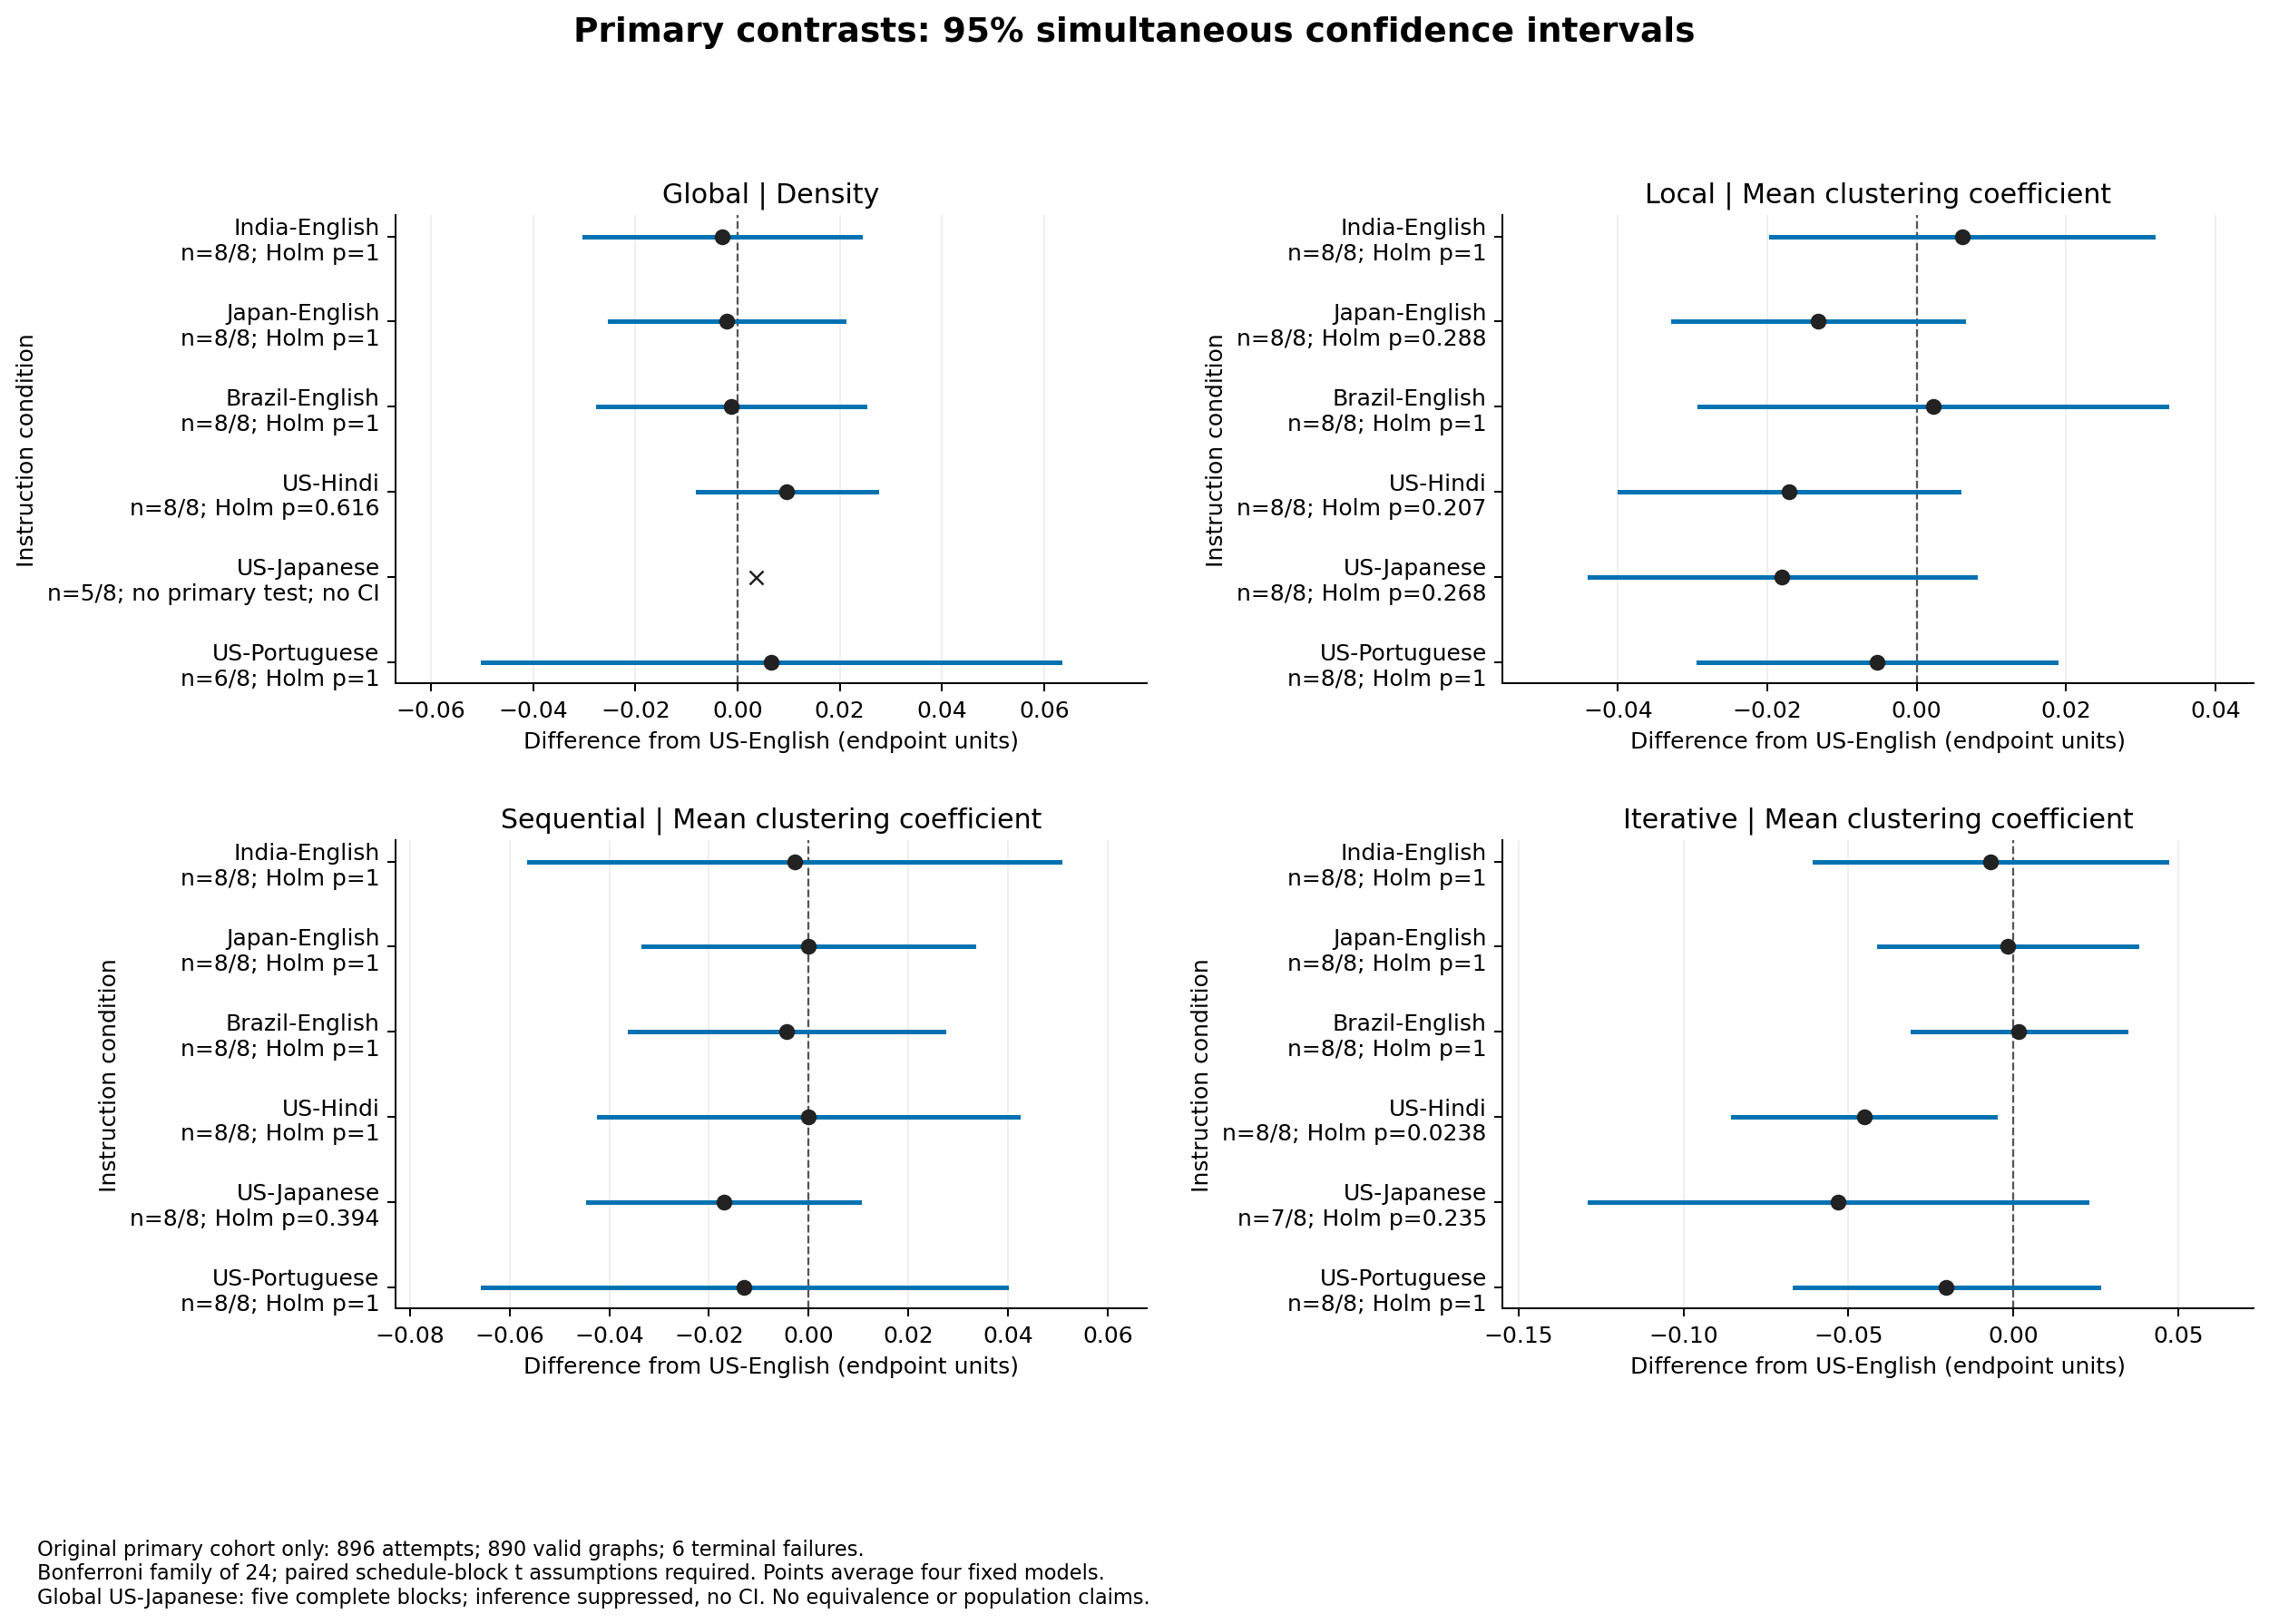

PNG and SVG copies live in the temporary workspace for this kernel session.

### 02 paired blocks
One dot per complete schedule block. Dots on both sides of zero show sign changes. Incomplete blocks are absent, not zero.

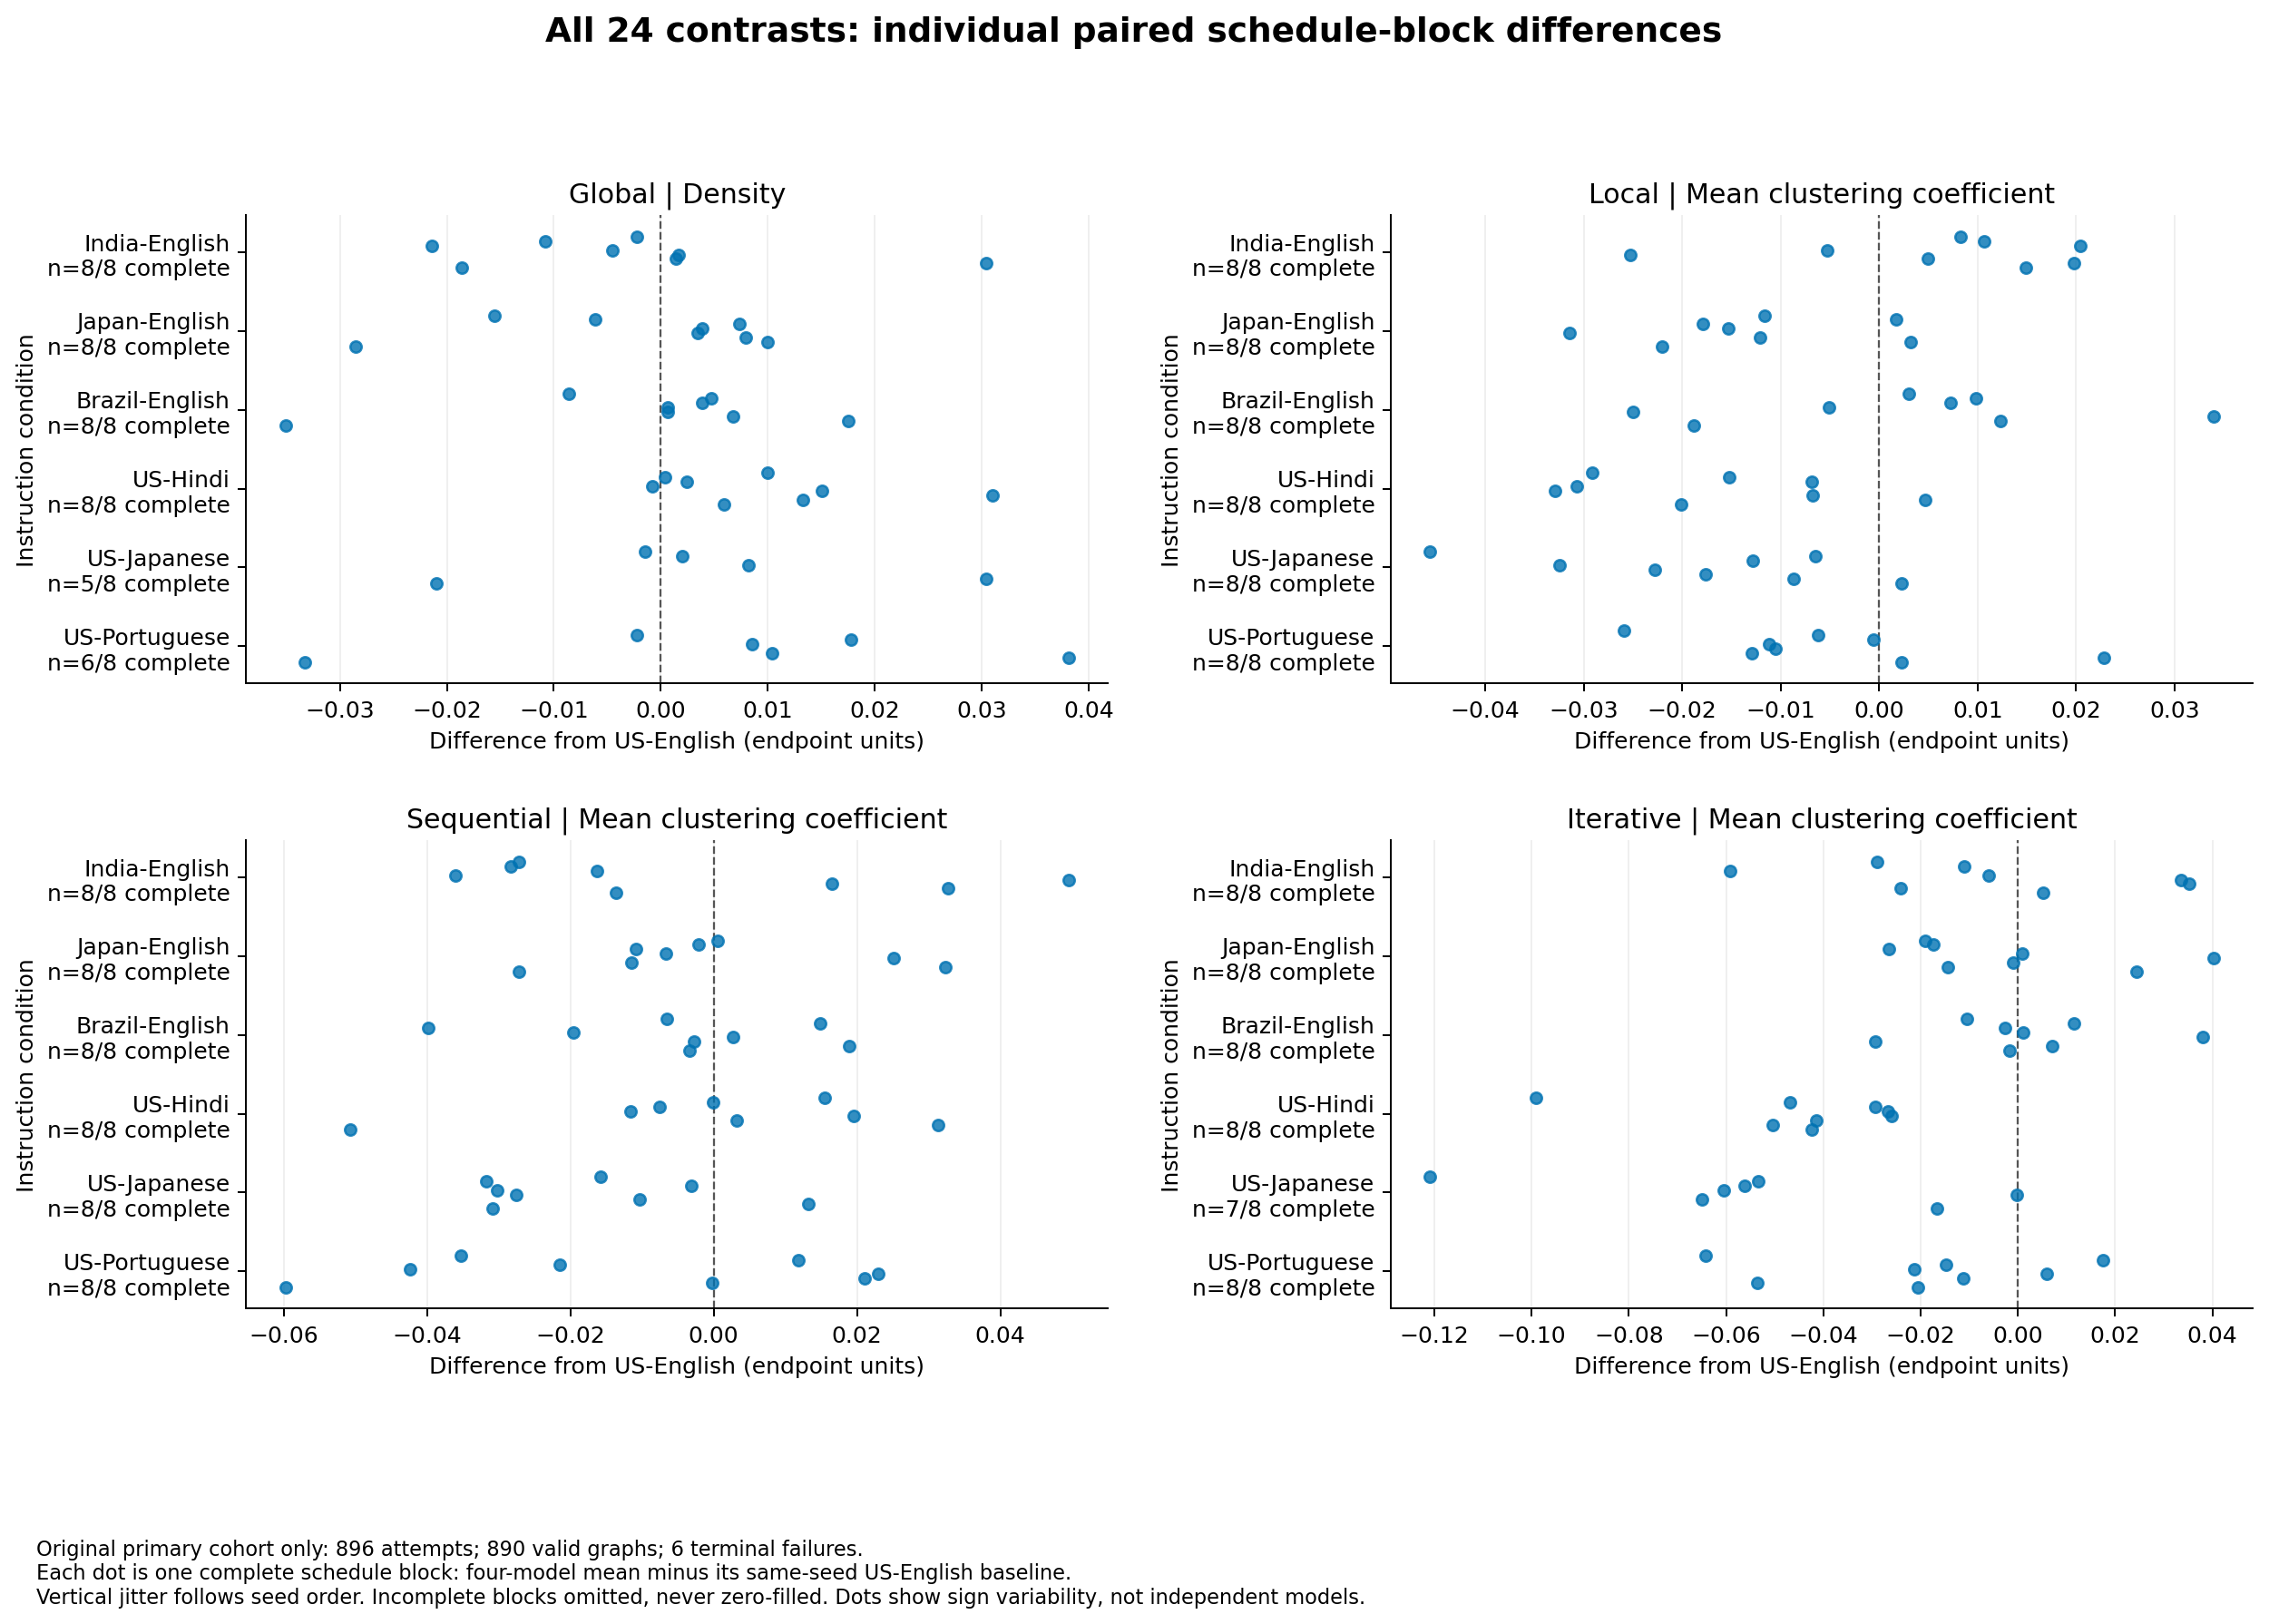

PNG and SVG copies live in the temporary workspace for this kernel session.

### 03 model endpoint means
Descriptive means for all four fixed models. Small numbers give defined endpoints out of eight attempts. Endpoints differ across methods.

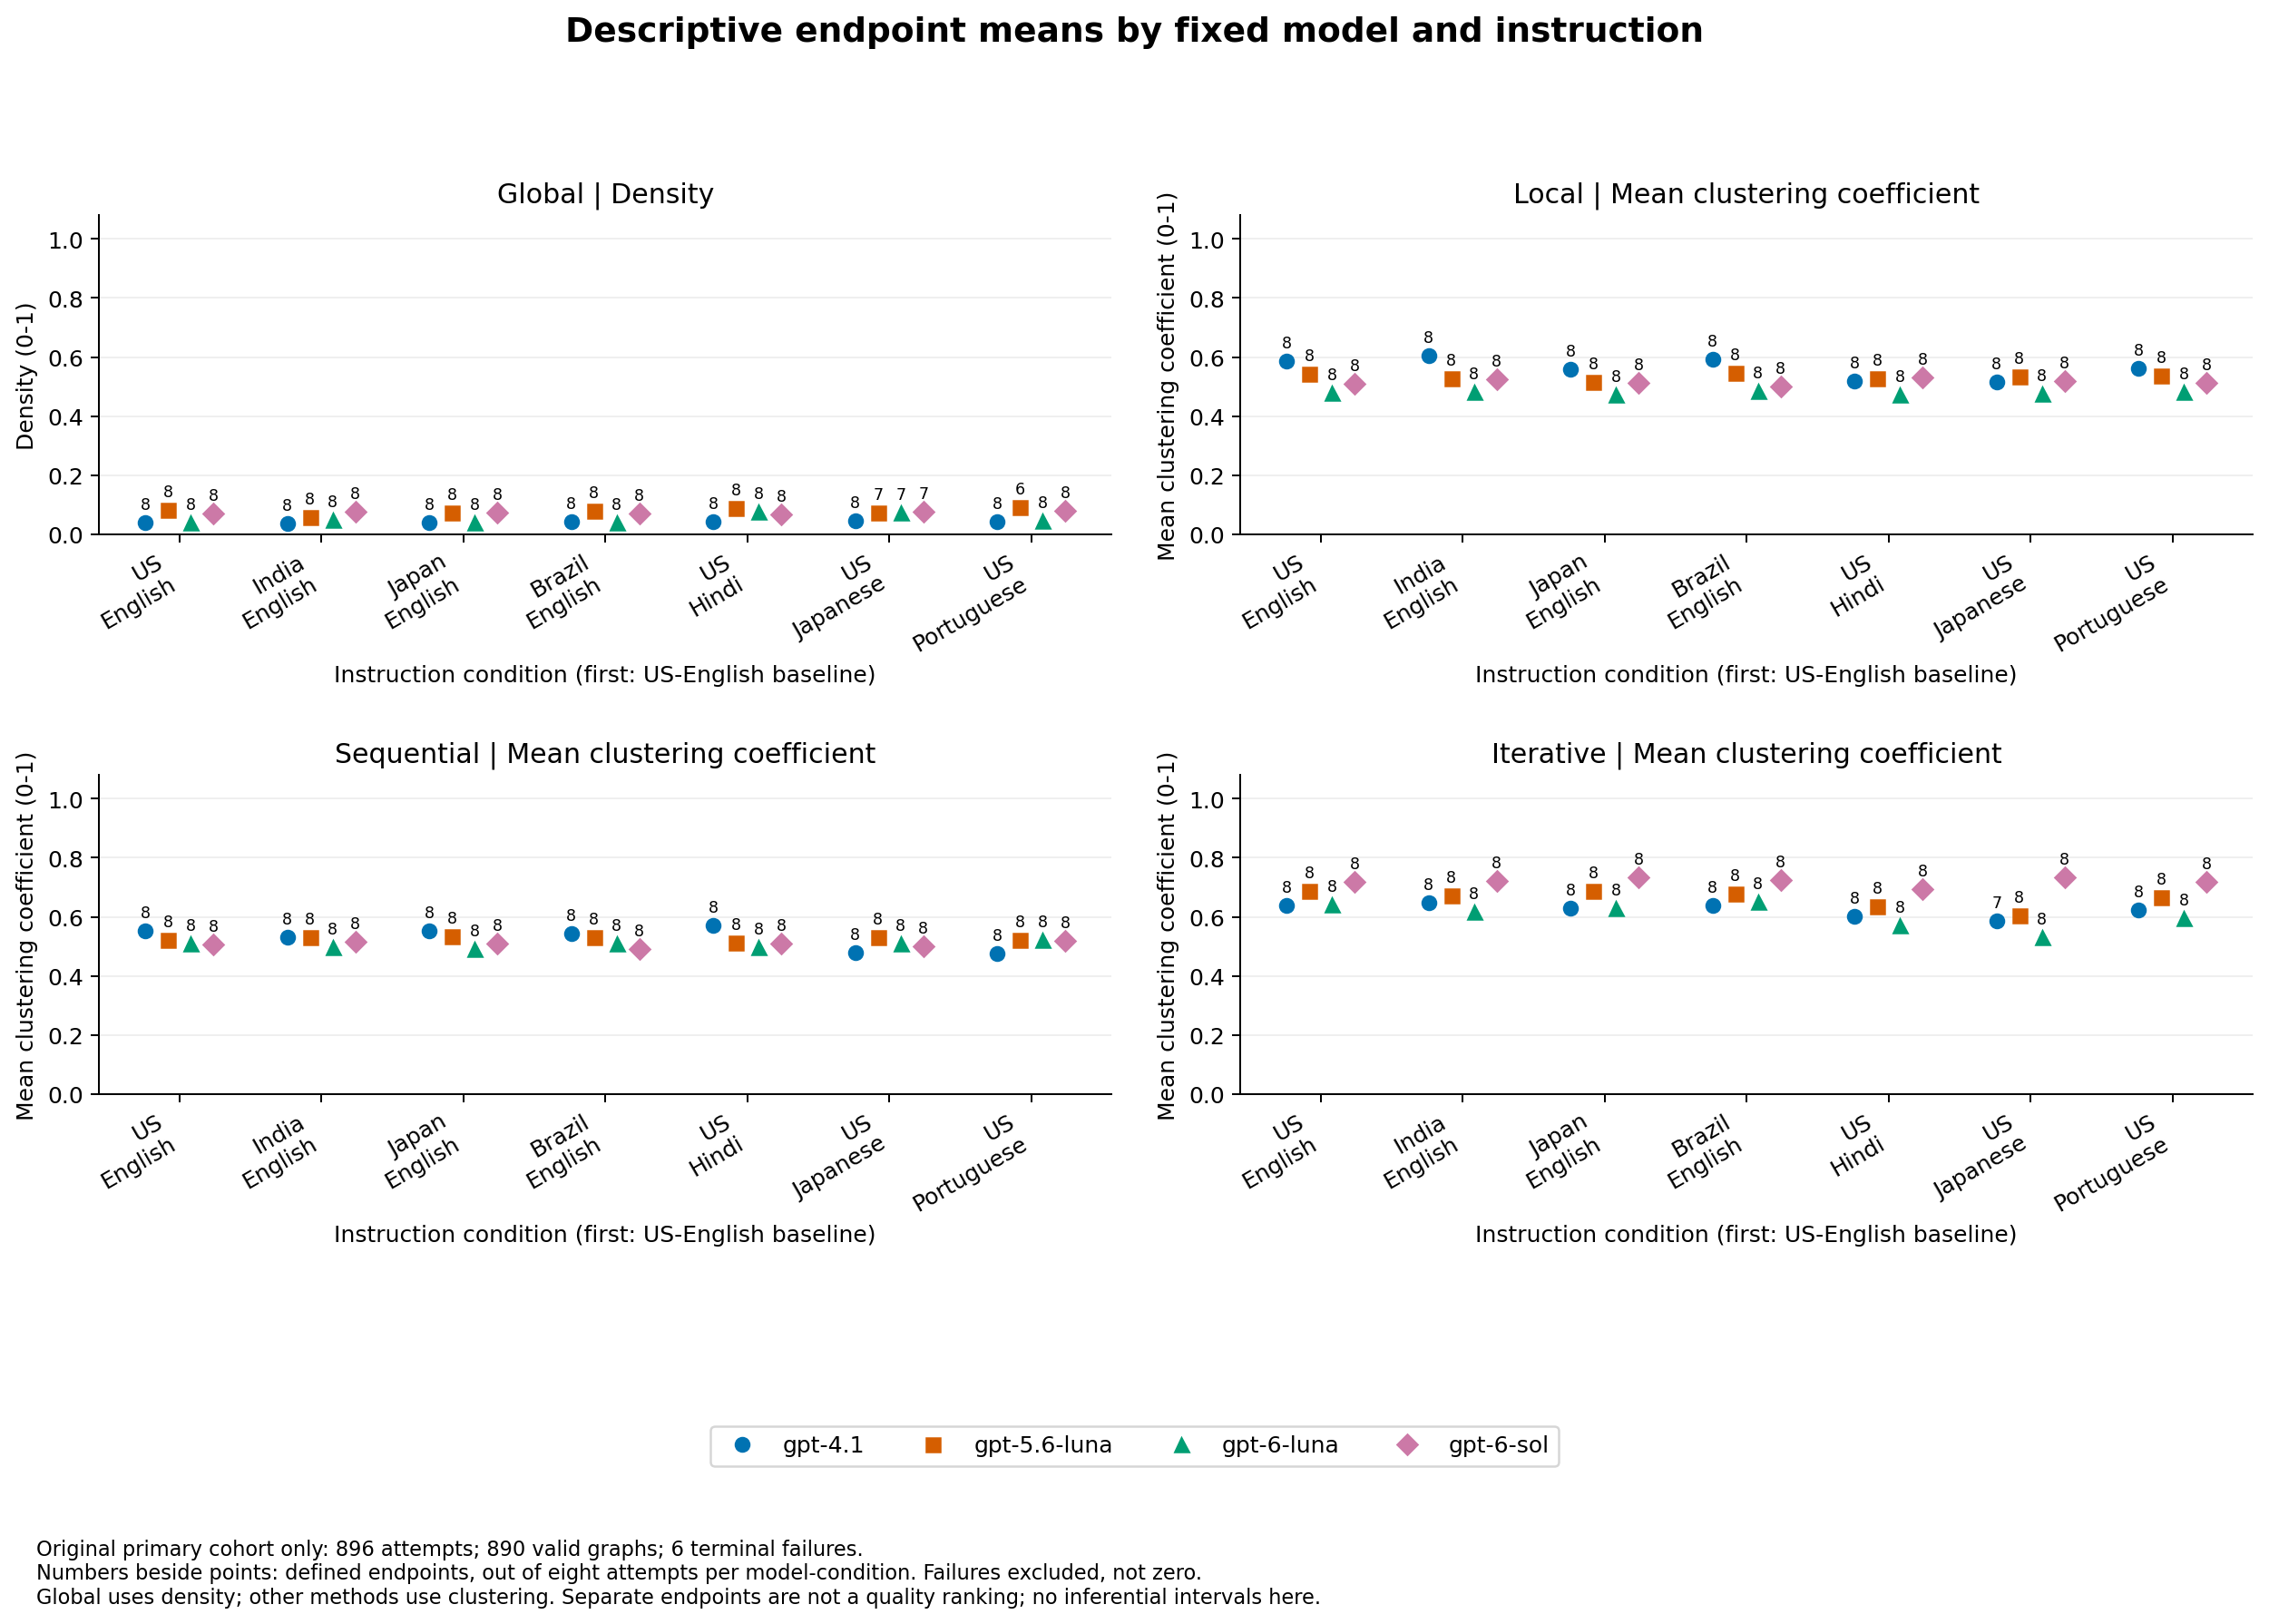

PNG and SVG copies live in the temporary workspace for this kernel session.

### 04 endpoint coverage
Every model-condition cell: defined endpoints out of attempts. F counts terminal failures; U counts valid graphs with undefined endpoints.

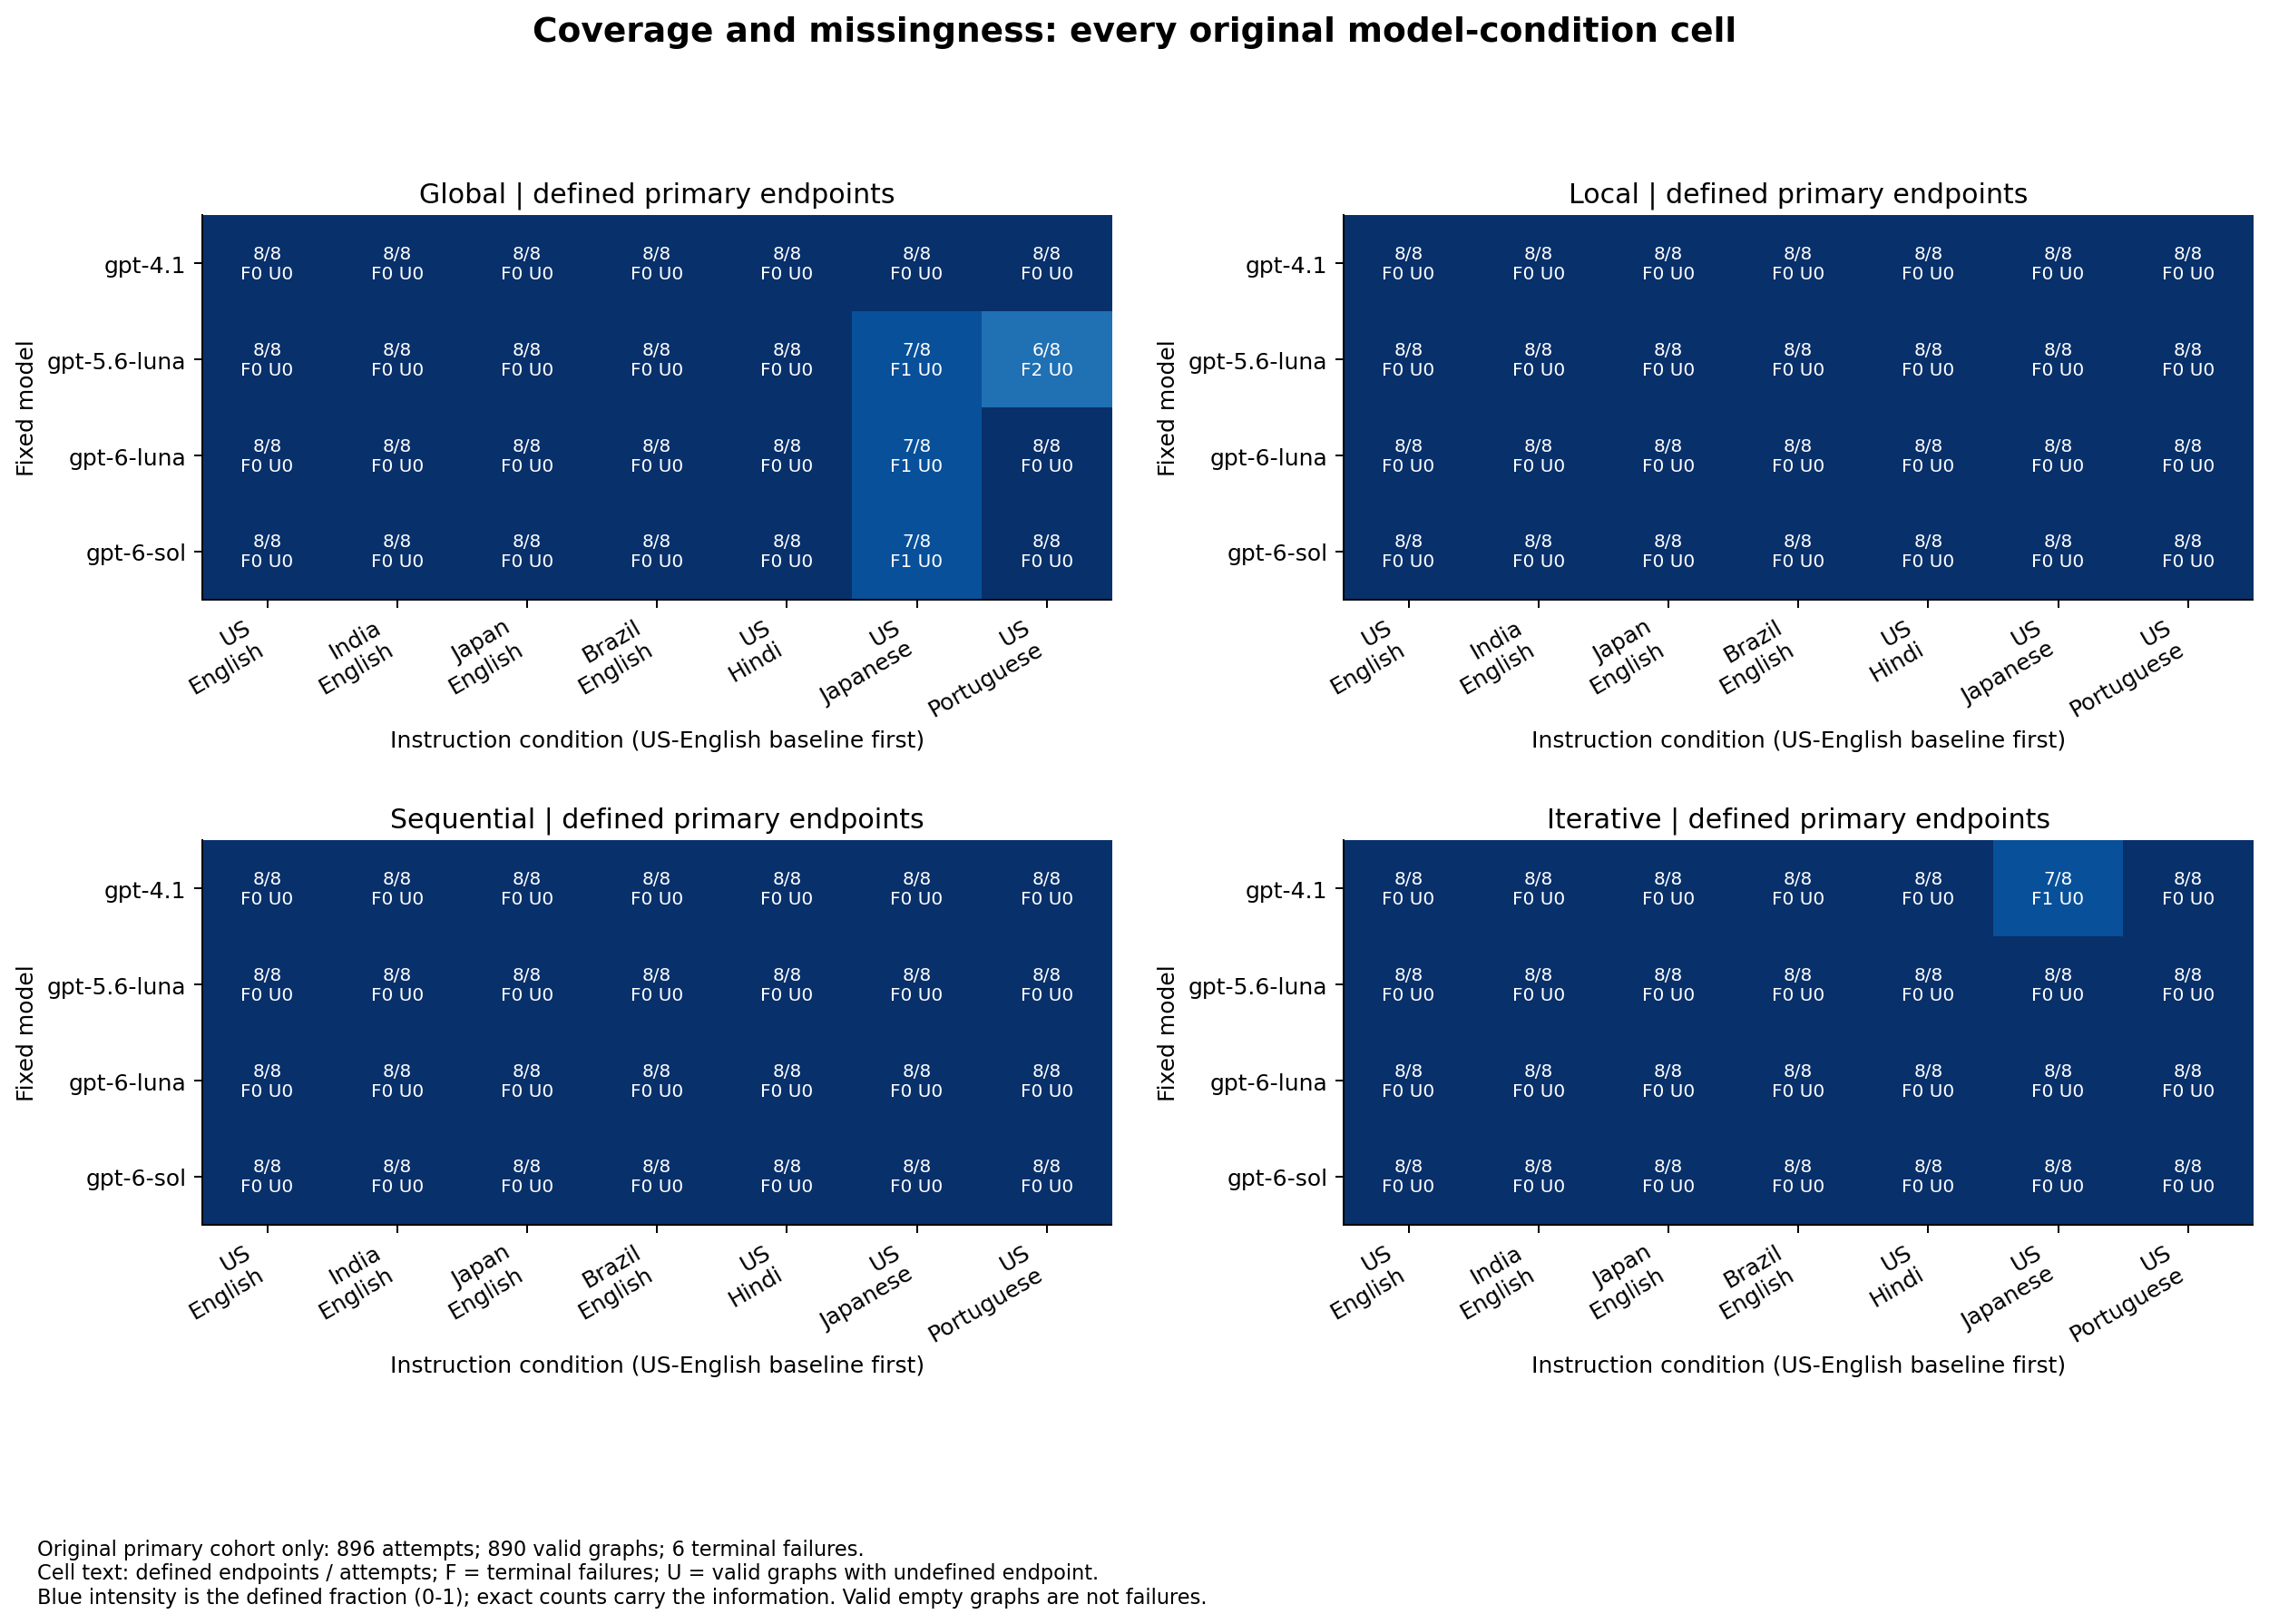

PNG and SVG copies live in the temporary workspace for this kernel session.

### 05 resource use
Received calls, estimated received cost, and serial API seconds. Call budgets differ. Failed attempts count; unallocated retained reservations do not. This is not an efficiency ranking.

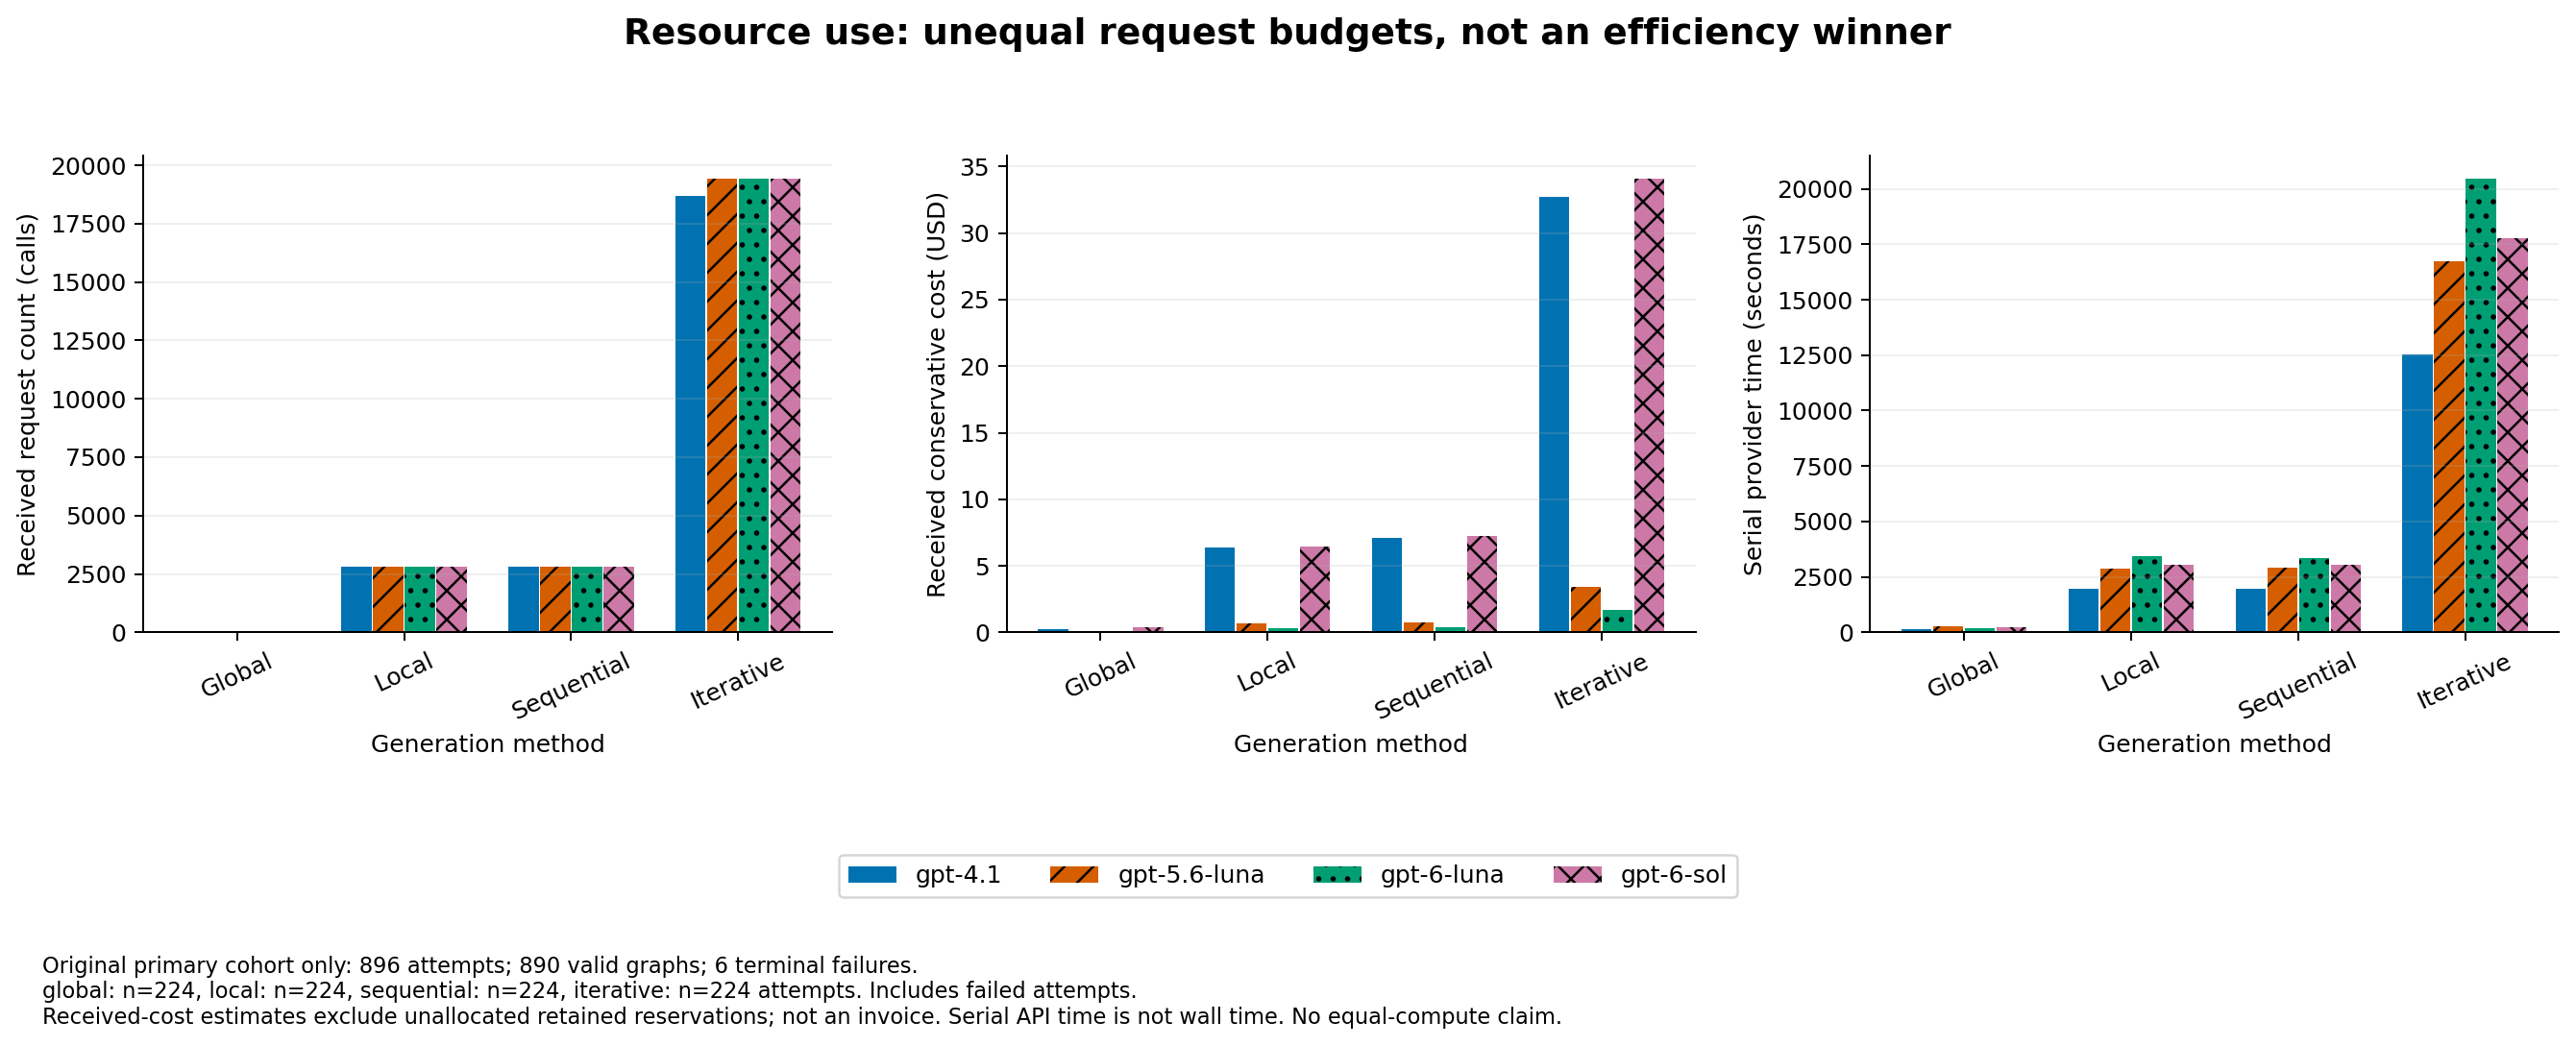

PNG and SVG copies live in the temporary workspace for this kernel session.

### 06 missingness bounds
Orange spans show possible mean differences when missing endpoints range from zero to one. These are identification bounds, not confidence intervals.

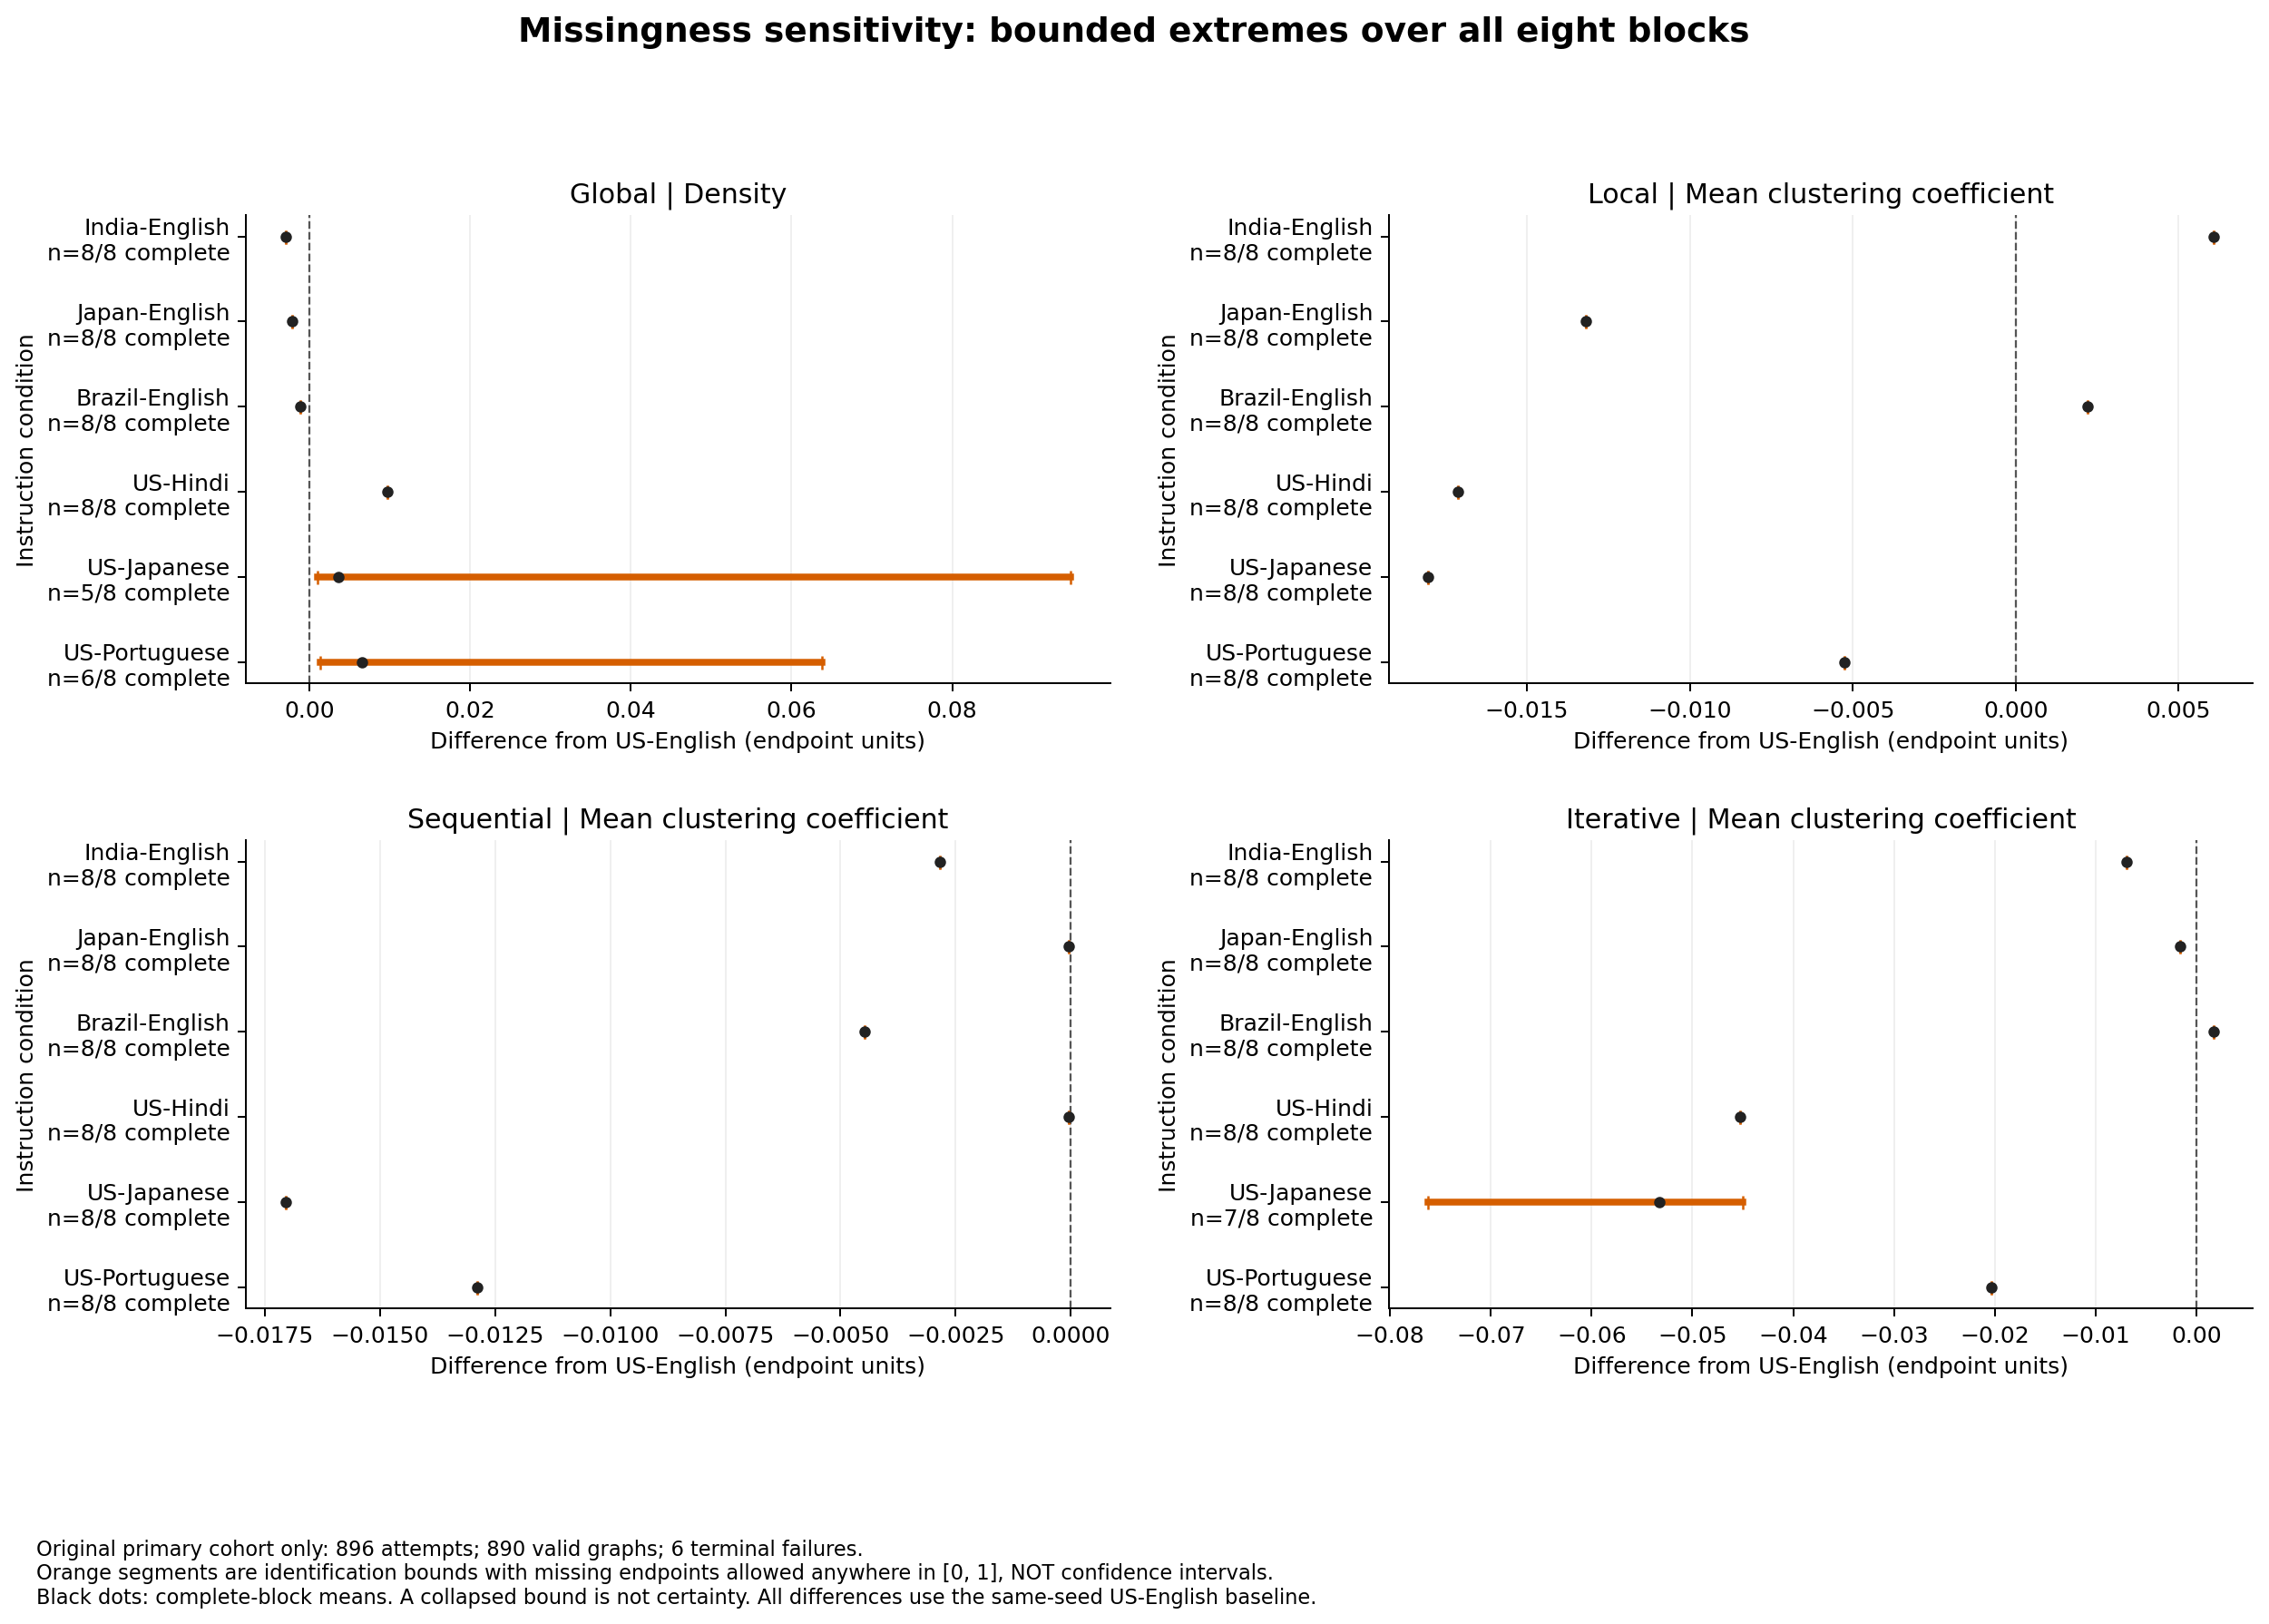

PNG and SVG copies live in the temporary workspace for this kernel session.

### 07 gnm clustering context
Each small mark compares one graph with its equal-node, equal-edge G(n,m) mean from eight draws. Outlined marks average those differences. All instruction conditions are pooled. No confidence intervals, new p-values, or realism claims.

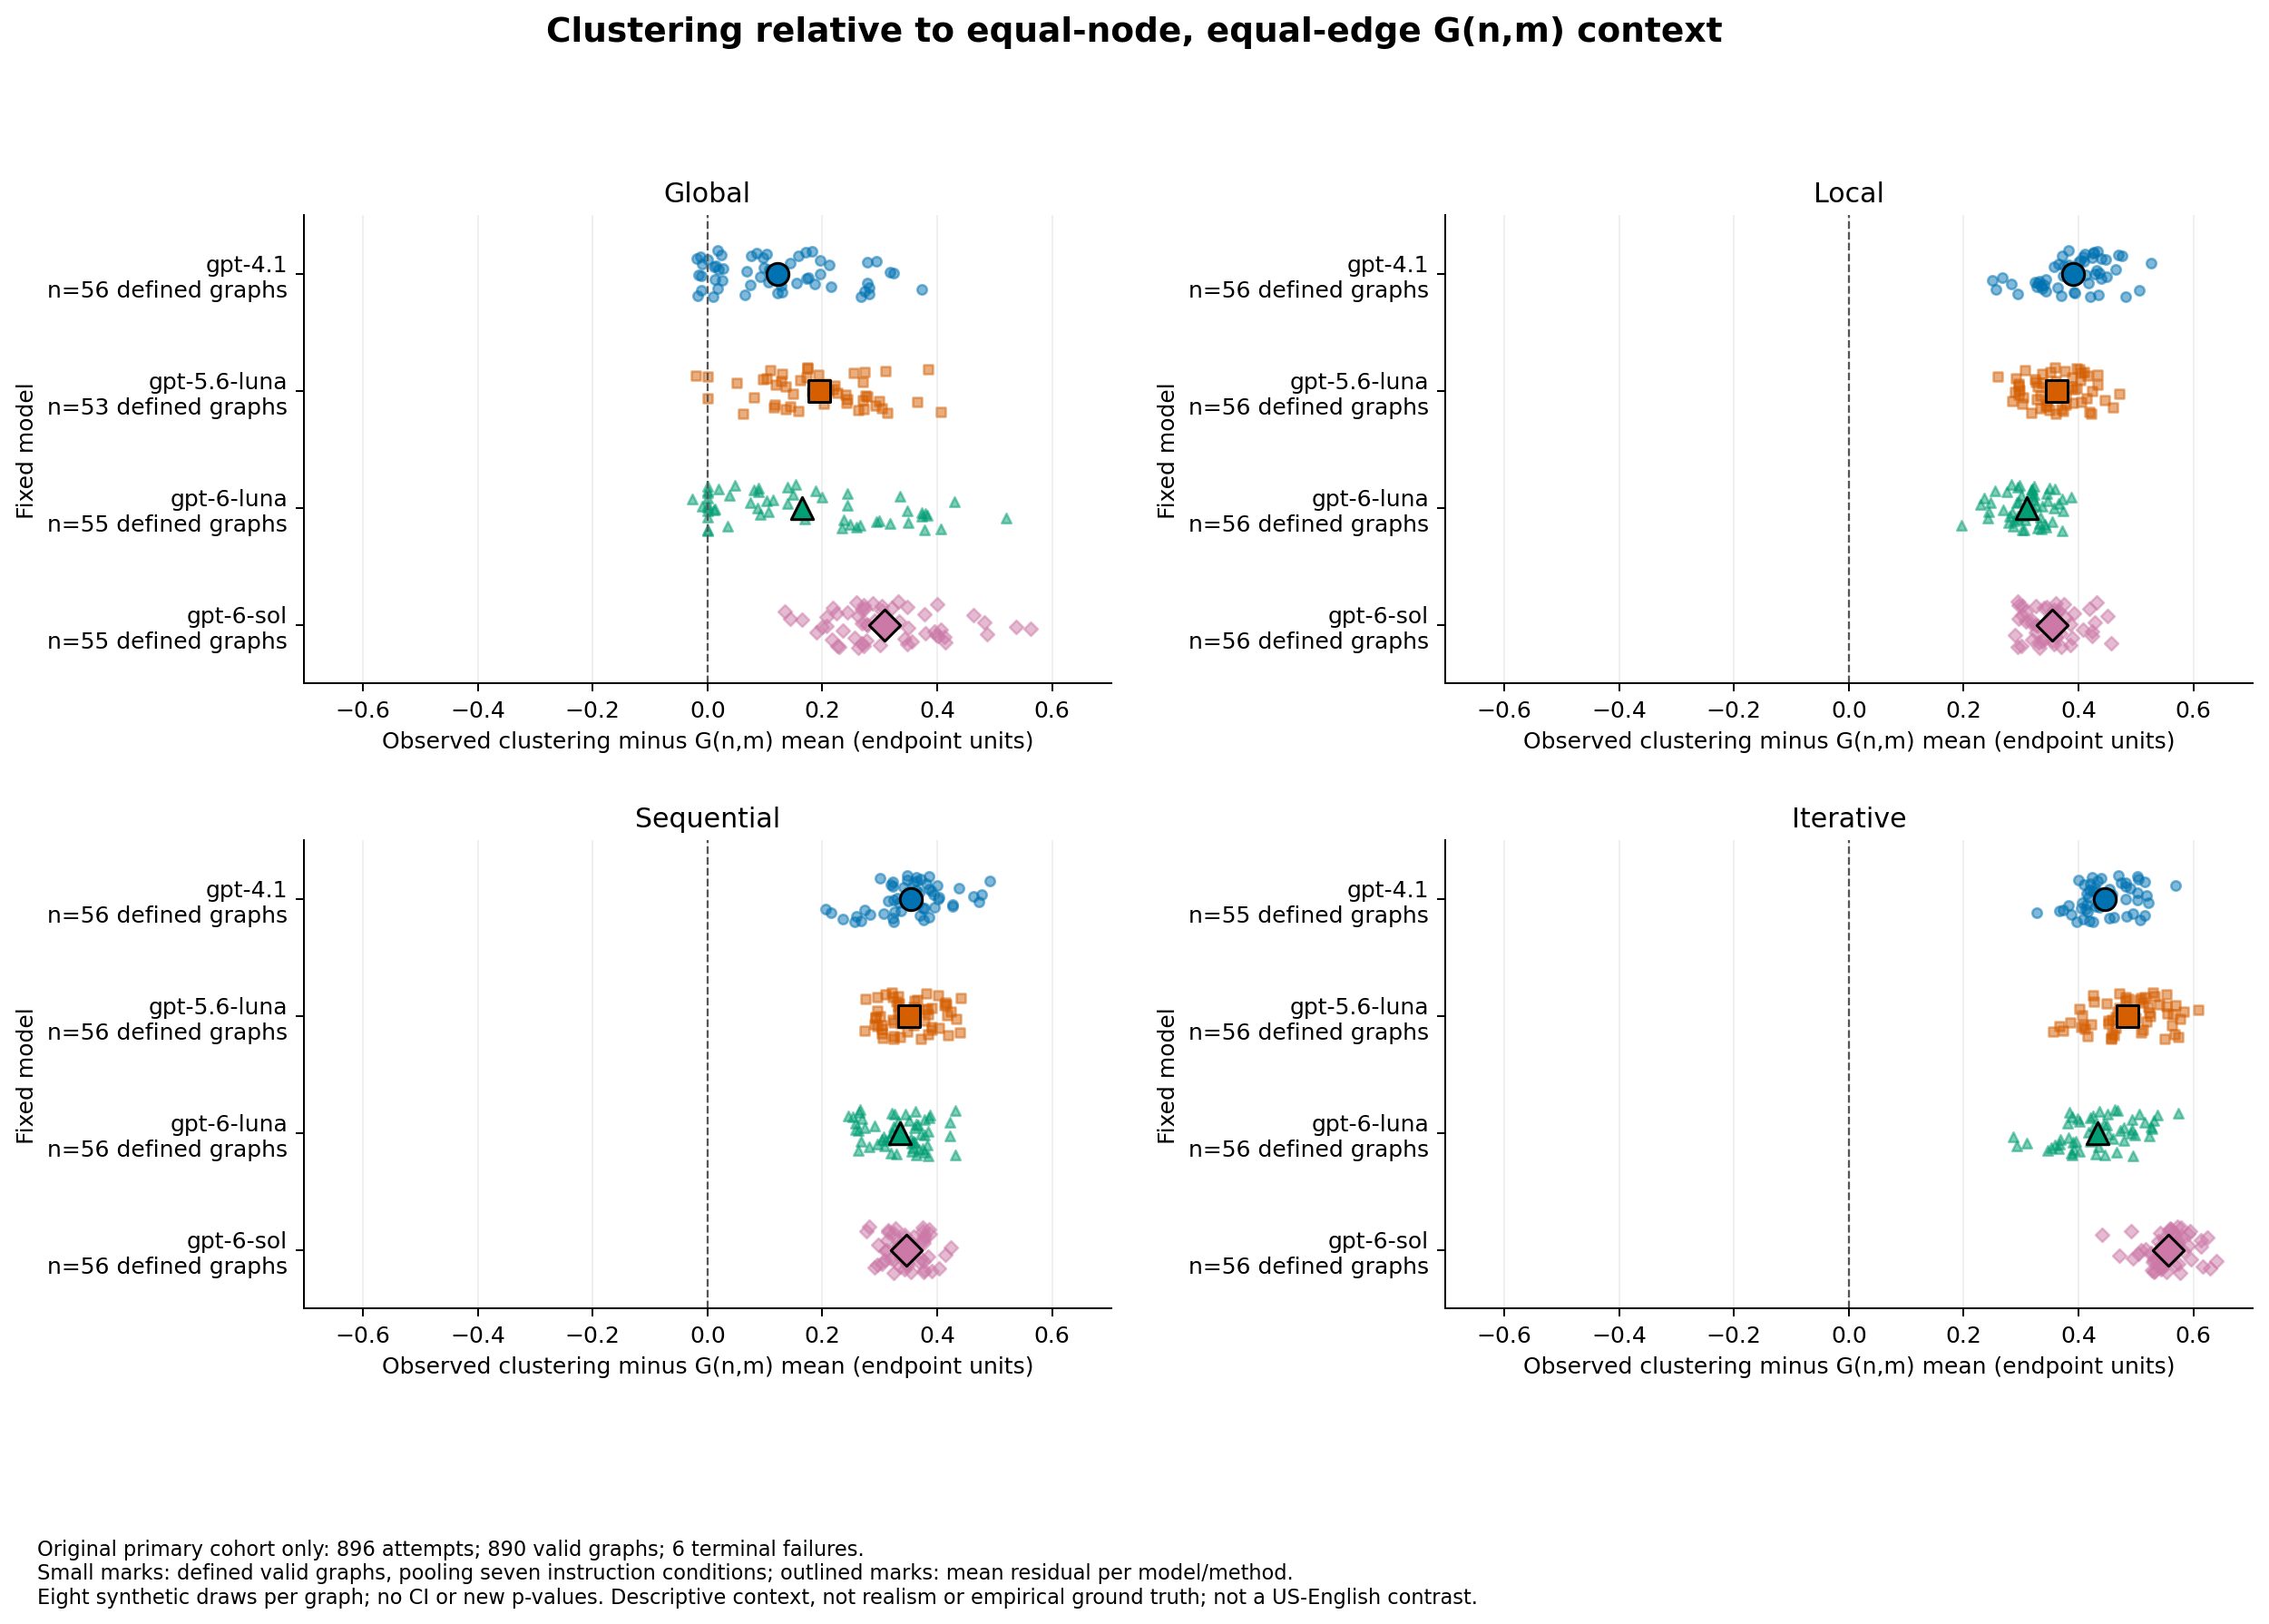

PNG and SVG copies live in the temporary workspace for this kernel session.

### 08 empirical context
Primary distributions by method, pooling fixed models and conditions, versus eight individually labeled published network records. Sizes and tie definitions differ; Tailor waves are not independent. Missing primary-CSV metrics are not filled. No tests, confidence intervals, winner, or realism claim.

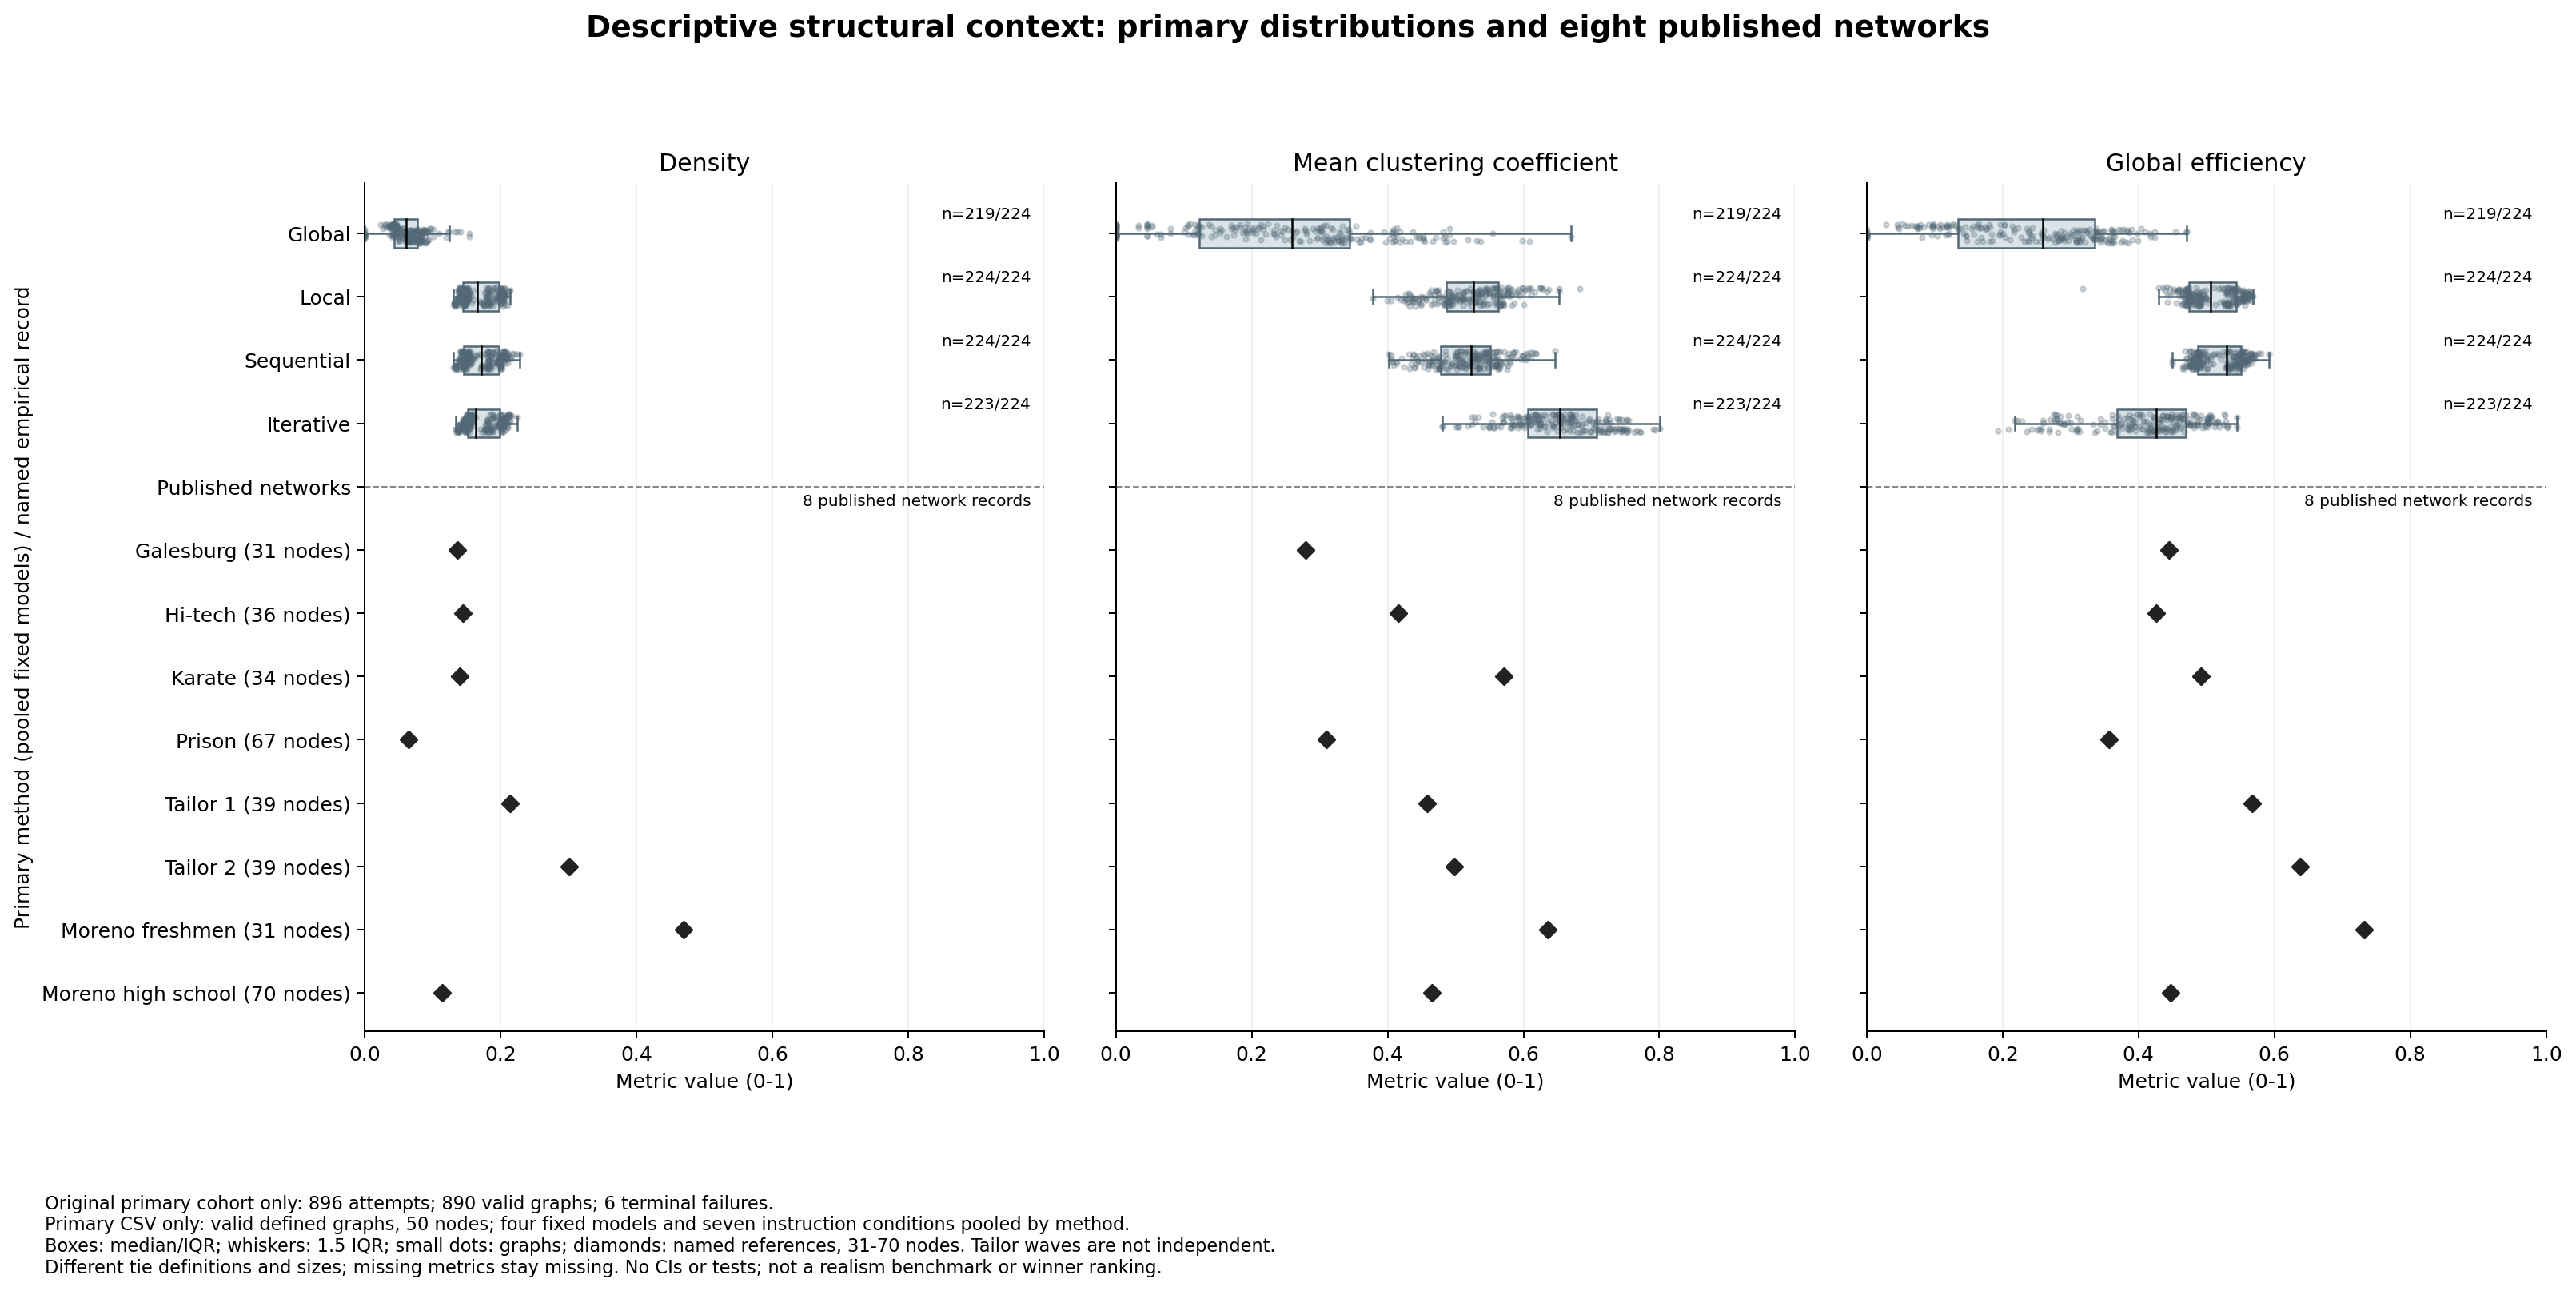

PNG and SVG copies live in the temporary workspace for this kernel session.

In [2]:
captions = {
    '01_primary_forest': 'Primary differences from US-English. Intervals cover the 24-contrast family under the stated assumptions. The five-block result has no CI.',
    '02_paired_blocks': 'One dot per complete schedule block. Dots on both sides of zero show sign changes. Incomplete blocks are absent, not zero.',
    '03_model_endpoint_means': 'Descriptive means for all four fixed models. Small numbers give defined endpoints out of eight attempts. Endpoints differ across methods.',
    '04_endpoint_coverage': 'Every model-condition cell: defined endpoints out of attempts. F counts terminal failures; U counts valid graphs with undefined endpoints.',
    '05_resource_use': 'Received calls, estimated received cost, and serial API seconds. Call budgets differ. Failed attempts count; unallocated retained reservations do not. This is not an efficiency ranking.',
    '06_missingness_bounds': 'Orange spans show possible mean differences when missing endpoints range from zero to one. These are identification bounds, not confidence intervals.',
    '07_gnm_clustering_context': 'Each small mark compares one graph with its equal-node, equal-edge G(n,m) mean from eight draws. Outlined marks average those differences. All instruction conditions are pooled. No confidence intervals, new p-values, or realism claims.',
    '08_empirical_context': 'Primary distributions by method, pooling fixed models and conditions, versus eight individually labeled published network records. Sizes and tie definitions differ; Tailor waves are not independent. Missing primary-CSV metrics are not filled. No tests, confidence intervals, winner, or realism claim.',
}
for name in figure_paths:
    path = Path(name)
    if path.suffix == '.png':
        display(Markdown('### ' + path.stem.replace('_', ' ') + '\n' + captions[path.stem]))
        display(Image(filename=str(path)))
        display(Markdown('PNG and SVG copies live in the temporary workspace for this kernel session.'))